# A/B-тест: геймификация на образовательной платформе

## 1. Контекст

Продуктовая команда EdTech-платформы выдвинула гипотезу: если добавить в личный кабинет ученика элементы геймификации — систему достижений за регулярное решение задач, — то это повысит вовлечённость и удержание учеников.

Для проверки гипотезы был запущен A/B-тест. Пользователи случайным образом разделены на две группы:

- **Группа A (контроль)** — старый интерфейс.
- **Группа B (тест)** — интерфейс с геймификацией.

Эксперимент длился 3 недели.

---

## 2. Цель проекта

Оценить успешность проведённого A/B-теста и принять аргументированное бизнес-решение:

1. **Раскатить** новую механику на всех пользователей, если эффект статистически и практически значим.
2. **Отправить на доработку**, если эффект есть только в отдельных сегментах или противоречив.
3. **Отказаться** от фичи, если эффект отсутствует или отрицательный.

---

## 3. Гипотеза

**H₀ (нулевая):** геймификация не влияет на Completion Rate и Retention (разницы между A и B нет).

**H₁ (альтернативная):** геймификация статистически значимо повышает Completion Rate и Retention.

---

## 4. Задачи проекта

1. **Подготовка данных**
   - объединить логи событий с таблицей групп;
   - очистить данные от ботов, дубликатов, конфликтов групп и выбросов.

2. **Sanity check**
   - проверить отсутствие пересечений между группами;
   - провести тест на равномерность сплита (SRM — Sample Ratio Mismatch).

3. **Расчёт продуктовых метрик**
   - Conversion Rate / Completion Rate;
   - Retention 7 и 14 дня;
   - Average Order Value (при наличии);
   - Time to Value (время до первого завершённого ДЗ).

4. **Разведочный анализ (EDA)**
   - распределения метрик;
   - воронка: логин → старт ДЗ → завершение ДЗ;
   - сравнение групп визуально.

5. **Статистическое тестирование**
   - выбор критерия: z-тест для долей, t-тест или U-критерий Манна—Уитни;
   - расчёт p-value и доверительных интервалов;
   - bootstrap для ненормальных распределений;
   - расчёт MDE (минимально обнаруживаемого эффекта).

6. **Интерпретация результатов**
   - оценка статистической значимости;
   - оценка практической (бизнес) значимости;
   - сегментный анализ (по классам, если применимо).

7. **Итоговый отчёт**
   - структурированный Jupyter Notebook с кодом, графиками и комментариями;
   - бизнес-презентация с финальной рекомендацией.


Выполнил: Замятин Кирилл

# Блок 0. Подготовка окружения

## Импорт библиотек

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

users = pd.read_csv("ab_test_users_groups.csv")
events = pd.read_csv("ab_test_events.csv")

print("users:", users.shape)
print("events:", events.shape)
print(users.head())
print(events.head())

users: (6008, 4)
events: (179330, 3)
   user_id group signup_date  grade
0  U300000     B  2026-03-09      5
1  U300001     B  2025-09-07      9
2  U300002     B  2026-01-11      9
3  U300003     A  2025-06-07      5
4  U300004     B  2025-12-25     11
   user_id            timestamp          event_type
0  U300281  2026-05-04 00:06:44  homework_completed
1  U300733  2026-05-04 00:19:56  homework_completed
2  U304499  2026-05-04 00:22:07               login
3  U304266  2026-05-04 00:23:42    homework_started
4  U304266  2026-05-04 00:23:42    homework_started


## Загрузка данных


In [4]:
users = pd.read_csv("ab_test_users_groups.csv")
events = pd.read_csv("ab_test_events.csv")

print("users:", users.shape)
print("events:", events.shape)
print()
print(users.head())
print()
print(events.head())

users: (6008, 4)
events: (179330, 3)

   user_id group signup_date  grade
0  U300000     B  2026-03-09      5
1  U300001     B  2025-09-07      9
2  U300002     B  2026-01-11      9
3  U300003     A  2025-06-07      5
4  U300004     B  2025-12-25     11

   user_id            timestamp          event_type
0  U300281  2026-05-04 00:06:44  homework_completed
1  U300733  2026-05-04 00:19:56  homework_completed
2  U304499  2026-05-04 00:22:07               login
3  U304266  2026-05-04 00:23:42    homework_started
4  U304266  2026-05-04 00:23:42    homework_started


# БЛОК 1. Очистка данных

## Шаг 1.1. Базовая проверка структуры

In [5]:
print("Всего строк в users:", len(users))
print("Уникальных user_id:", users["user_id"].nunique())
print("Дубликатов user_id:", users["user_id"].duplicated().sum())
print()
print("Всего строк в events:", len(events))
print("Уникальных user_id в events:", events["user_id"].nunique())

Всего строк в users: 6008
Уникальных user_id: 6000
Дубликатов user_id: 8

Всего строк в events: 179330
Уникальных user_id в events: 6000


## Шаг 1.2. Поиск конфликтов групп

In [6]:
conflict_users = (
    users.groupby("user_id")["group"]
    .nunique()
    .loc[lambda x: x > 1]
)

print("Пользователей с конфликтом групп:", len(conflict_users))
print(conflict_users)

Пользователей с конфликтом групп: 8
user_id
U300357    2
U300460    2
U300920    2
U301014    2
U301087    2
U301367    2
U301554    2
U305216    2
Name: group, dtype: int64


## Шаг 1.3. Проверка пропусков

In [7]:
print("Пропуски в users:")
print(users.isna().sum())
print()
print("Пропуски в events:")
print(events.isna().sum())

Пропуски в users:
user_id        0
group          0
signup_date    0
grade          0
dtype: int64

Пропуски в events:
user_id       0
timestamp     0
event_type    0
dtype: int64


## Шаг 1.4. Типы событий и период

In [8]:
print("Типы событий:")
print(events["event_type"].value_counts())
print()

# Преобразуем timestamp в дату
events["timestamp"] = pd.to_datetime(events["timestamp"])

print("Мин. событие:", events["timestamp"].min())
print("Макс. событие:", events["timestamp"].max())
days = (events["timestamp"].max() - events["timestamp"].min()).days
print("Длительность, дней:", days)

Типы событий:
login                 75552
homework_started      68317
homework_completed    28995
return_visit_d7        4519
return_visit_d14       1947
Name: event_type, dtype: int64

Мин. событие: 2026-05-04 00:06:44
Макс. событие: 2026-05-24 23:55:43
Длительность, дней: 20


## Шаг 1.5. Дубликаты событий

In [9]:
dup_count = events.duplicated().sum()
print("Полных дубликатов:", dup_count)

if dup_count > 0:
    print("\nПримеры дубликатов:")
    print(events[events.duplicated(keep=False)].sort_values(["user_id", "timestamp"]).head(10))

Полных дубликатов: 2

Примеры дубликатов:
       user_id           timestamp        event_type
3      U304266 2026-05-04 00:23:42  homework_started
4      U304266 2026-05-04 00:23:42  homework_started
86876  U304499 2026-05-14 13:49:54  homework_started
86877  U304499 2026-05-14 13:49:54  homework_started


## Шаг 1.6. Проверка ботов

In [10]:
user_activity = events.groupby("user_id").size().sort_values(ascending=False)

print("Топ-10 самых активных:")
print(user_activity.head(10))
print()
print("Среднее:", round(user_activity.mean(), 2))
print("Медиана:", round(user_activity.median(), 2))
print("Максимум:", user_activity.max())

threshold = user_activity.quantile(0.999)
print(f"\n99.9-й перцентиль: {threshold:.0f}")
print("Пользователей выше:", (user_activity > threshold).sum())

Топ-10 самых активных:
user_id
U303729    842
U304167    829
U305378    793
U302840    790
U304266    781
U300573    771
U300733    770
U302379    765
U300281    760
U300158    738
dtype: int64

Среднее: 29.89
Медиана: 28.0
Максимум: 842

99.9-й перцентиль: 770
Пользователей выше: 6


## Шаг 1.7. Сверка users и events

In [11]:
users_in_events = set(events["user_id"])
users_in_groups = set(users["user_id"])

no_group = users_in_events - users_in_groups
print("Пользователей в events без группы:", len(no_group))
print(list(no_group)[:20])

no_events = users_in_groups - users_in_events
print("\nПользователей в users без событий:", len(no_events))

Пользователей в events без группы: 0
[]

Пользователей в users без событий: 0


## Шаг 1.8. Финальная очистка

In [12]:
# 1. Убираем конфликтных пользователей из users
users_clean = users[~users["user_id"].isin(conflict_users.index)].copy()

# 2. Убираем дубликаты в users
users_clean = users_clean.drop_duplicates(subset="user_id", keep="first")

# 3. Убираем дубликаты в events
events_clean = events.drop_duplicates().copy()

# 4. Оставляем события только тех пользователей, кто есть в users_clean
events_clean = events_clean.merge(
    users_clean[["user_id", "group"]],
    on="user_id",
    how="inner"
)

print("После очистки:")
print("users_clean:", users_clean.shape)
print("events_clean:", events_clean.shape)
print()
print("Распределение по группам:")
print(users_clean["group"].value_counts())

После очистки:
users_clean: (5992, 4)
events_clean: (179111, 4)

Распределение по группам:
A    2997
B    2995
Name: group, dtype: int64


## Шаг 1.9. Проверка результата

In [13]:
print("Конфликтов групп:",
      users_clean.groupby("user_id")["group"].nunique().gt(1).sum())
print("Дубликатов в events:", events_clean.duplicated().sum())
print()
print("Событий по группам:")
print(events_clean["group"].value_counts())
print()
print("Уникальных пользователей по группам:")
print(events_clean.groupby("group")["user_id"].nunique())

Конфликтов групп: 0
Дубликатов в events: 0

Событий по группам:
B    96198
A    82913
Name: group, dtype: int64

Уникальных пользователей по группам:
group
A    2997
B    2995
Name: user_id, dtype: int64


## Выводы

В топ 10 есть сверхактивные пользователи.У пользователей в топ 10 750-840 событий. Выглядит странно, посмотрим в каких группах они находятся.

In [14]:
top_users = user_activity.head(10).index
print(users_clean[users_clean["user_id"].isin(top_users)][["user_id", "group"]])
print()
print("Распределение топ-10 по группам:")
print(users_clean[users_clean["user_id"].isin(top_users)]["group"].value_counts())

      user_id group
158   U300158     A
281   U300281     B
573   U300573     B
733   U300733     B
2379  U302379     A
2840  U302840     B
3729  U303729     B
4167  U304167     B
4266  U304266     A
5378  U305378     B

Распределение топ-10 по группам:
B    7
A    3
Name: group, dtype: int64


Посмотрим как ведет себя один из пользователей

In [15]:
# Смотрим на одного из них
sample_user = user_activity.index[0]
print(f"Пример событий пользователя {sample_user}:")
print(
    events_clean[events_clean["user_id"] == sample_user]
    .sort_values("timestamp")
    .head(30)
)

Пример событий пользователя U303729:
      user_id           timestamp          event_type group
3810  U303729 2026-05-04 00:28:33    homework_started     B
3811  U303729 2026-05-04 02:27:01  homework_completed     B
3812  U303729 2026-05-04 03:06:31  homework_completed     B
3813  U303729 2026-05-04 03:22:50               login     B
3814  U303729 2026-05-04 03:29:17    homework_started     B
3815  U303729 2026-05-04 03:57:38    homework_started     B
3816  U303729 2026-05-04 04:46:01               login     B
3817  U303729 2026-05-04 06:05:18    homework_started     B
3818  U303729 2026-05-04 07:16:26  homework_completed     B
3819  U303729 2026-05-04 07:43:30    homework_started     B
3820  U303729 2026-05-04 08:10:52               login     B
3821  U303729 2026-05-04 08:53:13  homework_completed     B
3822  U303729 2026-05-04 09:15:44    homework_started     B
3823  U303729 2026-05-04 09:18:47               login     B
3824  U303729 2026-05-04 09:28:34               login     B
382

 Сравним распределение активности А и В

In [16]:
activity_by_group = (
    events_clean.groupby(["group", "user_id"]).size()
    .reset_index(name="n_events")
)

print("Описательные статистики по группам:")
print(activity_by_group.groupby("group")["n_events"].describe(percentiles=[.5, .9, .99]))

Описательные статистики по группам:
        count       mean        std  min   50%   90%   99%    max
group                                                            
A      2997.0  27.665332  29.875539  9.0  27.0  34.0  40.0  780.0
B      2995.0  32.119533  37.581607  6.0  30.0  40.0  47.0  842.0


Посмотрим, сколько сверхактивных в каждой группе

In [17]:
activity_by_group["is_hyperactive"] = activity_by_group["n_events"] > 300

print("Сверхактивные (300+ событий):")
print(activity_by_group[activity_by_group["is_hyperactive"]].groupby("group").size())

Сверхактивные (300+ событий):
group
A    5
B    7
dtype: int64


Проверим временные паттерны

Активность по часам (топ-10):


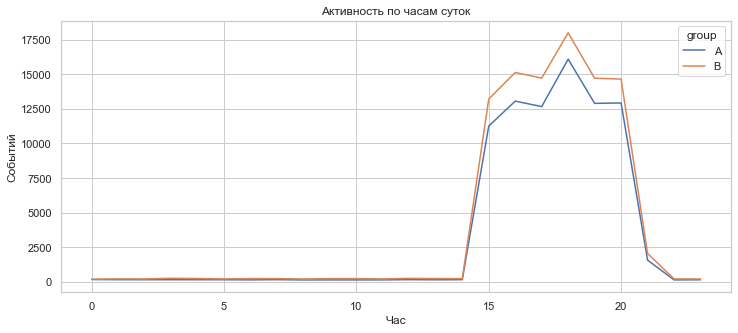

In [18]:
events_clean["hour"] = events_clean["timestamp"].dt.hour

# Активность по часам суток
hourly = events_clean.groupby(["group", "hour"]).size().unstack(0)

print("Активность по часам (топ-10):")
hourly.plot(figsize=(12, 5), title="Активность по часам суток")
plt.xlabel("Час")
plt.ylabel("Событий")
plt.show()

Проверим длительность сессий

In [19]:
# Для топ-5 пользователей посмотрим, есть ли «человеческие» паузы
for uid in user_activity.head(5).index:
    u = events_clean[events_clean["user_id"] == uid].sort_values("timestamp")
    gaps = u["timestamp"].diff().dt.total_seconds().div(3600)
    print(f"{uid}: медиана паузы = {gaps.median():.2f} ч, "
          f"мин = {gaps.min():.2f} ч, "
          f"доля пауз < 1 мин = {(gaps < 1/60).mean()*100:.1f}%")

U303729: медиана паузы = 0.38 ч, мин = 0.00 ч, доля пауз < 1 мин = 2.9%
U304167: медиана паузы = 0.41 ч, мин = 0.00 ч, доля пауз < 1 мин = 2.7%
U305378: медиана паузы = 0.40 ч, мин = 0.00 ч, доля пауз < 1 мин = 2.0%
U302840: медиана паузы = 0.45 ч, мин = 0.00 ч, доля пауз < 1 мин = 2.7%
U304266: медиана паузы = 0.46 ч, мин = 0.00 ч, доля пауз < 1 мин = 1.5%


После проверки, скорее всего это основные получатели эффекта геймификации. 
Медиана пауз	0.38–0.46 часа (23–28 мин)	Человеческий ритм
Паузы < 1 мин	1.5–2.9%	Не спам, нормально
Распределение по часам	Плавное, днём	Как у людей
Сверхактивных в A	5	Есть в обеих группах
Сверхактивных в B	7	Немного больше, но не аномально
99-й перцентиль	A=40, B=47	Основная масса — нормальная

# БЛОК 2. Sanity check и SRM

## Шаг 2.1. Формальная проверка SRM

In [21]:
observed = users_clean["group"].value_counts().sort_index().values
expected = [observed.sum() / 2, observed.sum() / 2]

chi2, p_srm = stats.chisquare(observed, expected)

print(f"Наблюдаемое:  A = {observed[0]}, B = {observed[1]}")
print(f"Ожидаемое:    A = {expected[0]:.0f}, B = {expected[1]:.0f}")
print(f"Chi² = {chi2:.4f}, p-value = {p_srm:.4f}")
print()

if p_srm < 0.05:
    print(" SRM обнаружен — результаты теста нельзя считать надёжными")
else:
    print("✓ SRM не обнаружен — сплит равномерный")

Наблюдаемое:  A = 2997, B = 2995
Ожидаемое:    A = 2996, B = 2996
Chi² = 0.0007, p-value = 0.9794

✓ SRM не обнаружен — сплит равномерный


## Шаг 2.2. Дополнительно: SRM по событиям

In [22]:
events_per_user = (
    events_clean.groupby(["group", "user_id"]).size()
    .reset_index(name="n")
)

print("Средне событий на пользователя:")
print(events_per_user.groupby("group")["n"].agg(["mean", "median", "std"]))

Средне событий на пользователя:
            mean  median        std
group                              
A      27.665332    27.0  29.875539
B      32.119533    30.0  37.581607


# БЛОК 3. Расчёт метрик по пользователю

## Шаг 3.1. Агрегация событий по пользователю

In [23]:
agg = events_clean.groupby("user_id").agg(
    group=("group", "first"),
    first_event=("timestamp", "min"),
    last_event=("timestamp", "max"),
    n_login=("event_type", lambda x: (x == "login").sum()),
    n_hw_started=("event_type", lambda x: (x == "homework_started").sum()),
    n_hw_completed=("event_type", lambda x: (x == "homework_completed").sum()),
    returned_d7=("event_type", lambda x: (x == "return_visit_d7").sum() > 0),
    returned_d14=("event_type", lambda x: (x == "return_visit_d14").sum() > 0),
).reset_index()

print("Строк в agg:", len(agg))
print(agg.head())

Строк в agg: 5992
   user_id group         first_event          last_event  n_login  \
0  U300000     B 2026-05-04 19:36:00 2026-05-22 15:29:00       14   
1  U300001     B 2026-05-04 20:12:00 2026-05-24 17:10:00       14   
2  U300002     B 2026-05-06 18:47:00 2026-05-24 18:04:00       12   
3  U300003     A 2026-05-04 19:43:00 2026-05-23 19:56:00       10   
4  U300004     B 2026-05-04 19:09:00 2026-05-22 16:24:00       13   

   n_hw_started  n_hw_completed  returned_d7  returned_d14  
0            11               6         True          True  
1            11               3         True          True  
2            11               4         True          True  
3            10               3         True          True  
4            12               3         True         False  


## Шаг 3.2. Основные продуктовые метрики

In [24]:
# 1. Завершил хотя бы одно ДЗ
agg["completed_any"] = agg["n_hw_completed"] > 0

# 2. Доля завершённых от начатых (у кого начатые есть)
agg["completion_rate"] = (
    agg["n_hw_completed"] / agg["n_hw_started"].replace(0, np.nan)
)

# 3. Time to Value — часы от первого события до первого завершённого ДЗ
first_login = (
    events_clean[events_clean["event_type"] == "login"]
    .groupby("user_id")["timestamp"].min()
    .rename("first_login")
)

first_hw_complete = (
    events_clean[events_clean["event_type"] == "homework_completed"]
    .groupby("user_id")["timestamp"].min()
    .rename("first_hw_complete")
)

agg = agg.merge(first_login, on="user_id", how="left")
agg = agg.merge(first_hw_complete, on="user_id", how="left")

agg["time_to_first_hw_hours"] = (
    (agg["first_hw_complete"] - agg["first_login"]).dt.total_seconds() / 3600
)

# 4. Retention как число (0/1)
agg["retention_7"] = agg["returned_d7"].astype(int)
agg["retention_14"] = agg["returned_d14"].astype(int)

print("Метрики посчитаны")
print(agg[["user_id", "group", "completed_any", "completion_rate",
           "time_to_first_hw_hours", "retention_7", "retention_14"]].head())

Метрики посчитаны
   user_id group  completed_any  completion_rate  time_to_first_hw_hours  \
0  U300000     B           True         0.545455              167.633333   
1  U300001     B           True         0.272727              188.950000   
2  U300002     B           True         0.363636               97.066667   
3  U300003     A           True         0.300000              117.583333   
4  U300004     B           True         0.250000                0.816667   

   retention_7  retention_14  
0            1             1  
1            1             1  
2            1             1  
3            1             1  
4            1             0  


## Шаг 3.3. Сводка по группам

In [25]:
summary = agg.groupby("group").agg(
    users=("user_id", "nunique"),
    completion_any_rate=("completed_any", "mean"),
    avg_completion_rate=("completion_rate", "mean"),
    avg_time_to_first_hw=("time_to_first_hw_hours", "mean"),
    median_time_to_first_hw=("time_to_first_hw_hours", "median"),
    retention_7_rate=("retention_7", "mean"),
    retention_14_rate=("retention_14", "mean"),
).round(4)

print("Сводка по группам:")
print(summary)

print("\nРазница B − A:")
diff = summary.loc["B"] - summary.loc["A"]
print(diff.round(4))

Сводка по группам:
       users  completion_any_rate  avg_completion_rate  avg_time_to_first_hw  \
group                                                                          
A       2997               0.9763               0.3471               88.6152   
B       2995               0.9883               0.4392               64.2265   

       median_time_to_first_hw  retention_7_rate  retention_14_rate  
group                                                                
A                      50.2333            0.7271             0.2876  
B                      25.2333            0.7796             0.3623  

Разница B − A:
users                      -2.0000
completion_any_rate         0.0120
avg_completion_rate         0.0921
avg_time_to_first_hw      -24.3887
median_time_to_first_hw   -25.0000
retention_7_rate            0.0525
retention_14_rate           0.0747
dtype: float64


## Шаг 3.4. Проверка распределений метрик

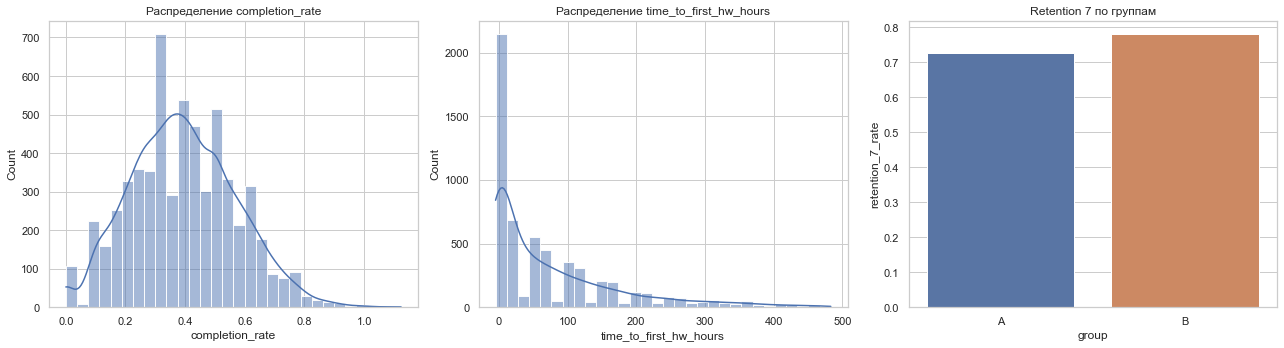

Shapiro-Wilk для time_to_first_hw: stat=0.7795, p=0.0000e+00
Распределение НЕ нормальное — используем Манна—Уитни


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Completion rate
sns.histplot(agg["completion_rate"].dropna(), bins=30, ax=axes[0], kde=True)
axes[0].set_title("Распределение completion_rate")

# Time to value
sns.histplot(agg["time_to_first_hw_hours"].dropna(), bins=30, ax=axes[1], kde=True)
axes[1].set_title("Распределение time_to_first_hw_hours")

# Retention (бар)
sns.barplot(data=summary.reset_index(), x="group", y="retention_7_rate", ax=axes[2])
axes[2].set_title("Retention 7 по группам")

plt.tight_layout()
plt.show()

# Тест Шапиро-Уилка на нормальность (по 5000 сэмплам)
sample = agg["time_to_first_hw_hours"].dropna().sample(5000, random_state=42)
stat, p_shapiro = stats.shapiro(sample)
print(f"Shapiro-Wilk для time_to_first_hw: stat={stat:.4f}, p={p_shapiro:.4e}")

if p_shapiro < 0.05:
    print("Распределение НЕ нормальное — используем Манна—Уитни")
else:
    print("Распределение близко к нормальному — можно t-тест")

# Вывод 

Метрика	A	B	Разница (B−A)
Completion any rate	97.63%	98.83%	+1.20 п.п.
Avg completion rate	34.71%	43.92%	+9.21 п.п.
Time to first HW (среднее)	88.6 ч	64.2 ч	−24.4 ч
Time to first HW (медиана)	50.2 ч	25.2 ч	−25.0 ч
Retention 7	72.71%	77.96%	+5.25 п.п.
Retention 14	28.76%	36.23%	+7.47 п.п.
Геймификация повышает все - завершение, скорость, удержание. Особенно сильно retention 14 +26%. time to value сократилось в 2 раза. Продолжаем проверку.

# БЛОК 4. Статистические тесты

## Шаг 4.1. Z-тест для долей

In [27]:
from statsmodels.stats.proportion import proportions_ztest

def test_proportion(agg, col, group_a="A", group_b="B"):
    a = agg.loc[agg["group"] == group_a, col]
    b = agg.loc[agg["group"] == group_b, col]

    count = np.array([b.sum(), a.sum()])
    nobs = np.array([len(b), len(a)])
    stat, pval = proportions_ztest(count, nobs)

    p_a = a.mean()
    p_b = b.mean()
    diff = p_b - p_a

    print(f"\n=== {col} ===")
    print(f"A: {p_a:.4f} ({p_a*100:.2f}%)")
    print(f"B: {p_b:.4f} ({p_b*100:.2f}%)")
    print(f"Разница B−A: {diff:+.4f} ({diff*100:+.2f} п.п.)")
    print(f"z-статистика: {stat:.4f}")
    print(f"p-value: {pval:.4e}")

    if pval < 0.001:
        print("→ p < 0.001 — очень высокая значимость")
    elif pval < 0.05:
        print("→ p < 0.05 — статистически значимо")
    else:
        print("→ p ≥ 0.05 — НЕ значимо")

    return pval

p_completed = test_proportion(agg, "completed_any")
p_ret7 = test_proportion(agg, "retention_7")
p_ret14 = test_proportion(agg, "retention_14")


=== completed_any ===
A: 0.9763 (97.63%)
B: 0.9883 (98.83%)
Разница B−A: +0.0120 (+1.20 п.п.)
z-статистика: 3.5245
p-value: 4.2427e-04
→ p < 0.001 — очень высокая значимость

=== retention_7 ===
A: 0.7271 (72.71%)
B: 0.7796 (77.96%)
Разница B−A: +0.0526 (+5.26 п.п.)
z-статистика: 4.7203
p-value: 2.3553e-06
→ p < 0.001 — очень высокая значимость

=== retention_14 ===
A: 0.2876 (28.76%)
B: 0.3623 (36.23%)
Разница B−A: +0.0746 (+7.46 п.п.)
z-статистика: 6.1690
p-value: 6.8738e-10
→ p < 0.001 — очень высокая значимость


## Шаг 4.2. Манн—Уитни для непрерывных метрик

In [28]:
from scipy.stats import mannwhitneyu

def test_mannwhitney(agg, col, group_a="A", group_b="B"):
    a = agg.loc[agg["group"] == group_a, col].dropna()
    b = agg.loc[agg["group"] == group_b, col].dropna()

    stat, pval = mannwhitneyu(a, b, alternative="two-sided")

    print(f"\n=== {col} ===")
    print(f"A: n={len(a)}, median={a.median():.4f}, mean={a.mean():.4f}")
    print(f"B: n={len(b)}, median={b.median():.4f}, mean={b.mean():.4f}")
    print(f"U-статистика: {stat:.0f}")
    print(f"p-value: {pval:.4e}")

    if pval < 0.001:
        print("→ p < 0.001 — очень высокая значимость")
    elif pval < 0.05:
        print("→ p < 0.05 — статистически значимо")
    else:
        print("→ p ≥ 0.05 — НЕ значимо")

    return pval

p_compl_rate = test_mannwhitney(agg, "completion_rate")
p_time = test_mannwhitney(agg, "time_to_first_hw_hours")


=== completion_rate ===
A: n=2997, median=0.3333, mean=0.3471
B: n=2995, median=0.4444, mean=0.4392
U-статистика: 3144690
p-value: 1.1473e-89
→ p < 0.001 — очень высокая значимость

=== time_to_first_hw_hours ===
A: n=2926, median=50.2333, mean=88.6152
B: n=2960, median=25.2333, mean=64.2265
U-статистика: 4981422
p-value: 1.7474e-23
→ p < 0.001 — очень высокая значимость


## Шаг 4.3. Доверительные интервалы для разницы долей

In [29]:
def ci_diff_proportions(agg, col, group_a="A", group_b="B", alpha=0.05):
    a = agg.loc[agg["group"] == group_a, col]
    b = agg.loc[agg["group"] == group_b, col]

    p_a, n_a = a.mean(), len(a)
    p_b, n_b = b.mean(), len(b)

    diff = p_b - p_a
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)

    z = stats.norm.ppf(1 - alpha / 2)
    lo, hi = diff - z * se, diff + z * se

    print(f"\n=== {col} ===")
    print(f"Разница B−A: {diff*100:+.2f} п.п.")
    print(f"95% ДИ: [{lo*100:+.2f}; {hi*100:+.2f}] п.п.")
    return diff, lo, hi

ci_diff_proportions(agg, "completed_any")
ci_diff_proportions(agg, "retention_7")
ci_diff_proportions(agg, "retention_14")


=== completed_any ===
Разница B−A: +1.20 п.п.
95% ДИ: [+0.53; +1.87] п.п.

=== retention_7 ===
Разница B−A: +5.26 п.п.
95% ДИ: [+3.08; +7.44] п.п.

=== retention_14 ===
Разница B−A: +7.46 п.п.
95% ДИ: [+5.10; +9.83] п.п.


(0.07464949646363112, 0.0510073012524825, 0.09829169167477973)

## Шаг 4.4. Bootstrap для completion_rate и time_to_first_hw

In [30]:
def bootstrap_ci(agg, col, group_a="A", group_b="B",
                 n_boot=10000, alpha=0.05, random_state=42):
    rng = np.random.default_rng(random_state)
    a = agg.loc[agg["group"] == group_a, col].dropna().values
    b = agg.loc[agg["group"] == group_b, col].dropna().values

    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, len(a), replace=True)
        sb = rng.choice(b, len(b), replace=True)
        diffs[i] = np.median(sb) - np.median(sa)

    lo, hi = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    point = np.median(b) - np.median(a)

    print(f"\n=== {col} (медиана) ===")
    print(f"Разница B−A (медиана): {point:+.4f}")
    print(f"95% bootstrap ДИ: [{lo:+.4f}; {hi:+.4f}]")
    return point, lo, hi

bootstrap_ci(agg, "completion_rate")
bootstrap_ci(agg, "time_to_first_hw_hours")


=== completion_rate (медиана) ===
Разница B−A (медиана): +0.1111
95% bootstrap ДИ: [+0.0952; +0.1212]

=== time_to_first_hw_hours (медиана) ===
Разница B−A (медиана): -25.0000
95% bootstrap ДИ: [-27.1667; -23.3167]


(-25.0, -27.166666666666664, -23.316666666666663)

## Шаг 4.5. Сводная таблица результатов

In [31]:
results = pd.DataFrame({
    "Метрика": [
        "completed_any",
        "retention_7",
        "retention_14",
        "completion_rate",
        "time_to_first_hw_hours",
    ],
    "Тест": ["z-тест", "z-тест", "z-тест", "Манн—Уитни", "Манн—Уитни"],
    "p-value": [p_completed, p_ret7, p_ret14, p_compl_rate, p_time],
})

results["значимо (α=0.05)"] = results["p-value"] < 0.05

print(results.to_string(index=False))

               Метрика       Тест      p-value  значимо (α=0.05)
         completed_any     z-тест 4.242722e-04              True
           retention_7     z-тест 2.355311e-06              True
          retention_14     z-тест 6.873829e-10              True
       completion_rate Манн—Уитни 1.147281e-89              True
time_to_first_hw_hours Манн—Уитни 1.747420e-23              True


# Вывод

Все метрики статистически значимы.
Доверительные интервалы (не содержат 0 — эффект подтверждён):
completion_any: [+0.53; +1.87] п.п.
retention_7: [+3.08; +7.44] п.п.
retention_14: [+5.10; +9.83] п.п.
completion_rate (медиана): [+9.52; +12.12] п.п.
time_to_first_hw (медиана): [−27.2; −23.3] ч
Вывод: H₀ отвергается. Геймификация даёт реальный эффект по всем метрикам.

# БЛОК 5. MDE — минимально обнаруживаемый эффект

## Шаг 5.1. Что такое MDE и зачем он нужен
Что делаем: считаем, какой минимальный эффект тест мог бы обнаружить при текущем размере выборки.

Зачем: p-value говорит «есть эффект», а MDE говорит «какой минимальный эффект мы способны были поймать». Если MDE большой, а эффект маленький — тест слабый. Если MDE маленький и эффект его превышает — тест мощный.

## Шаг 5.2. Расчёт MDE для долей

In [32]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

def mde_proportion(p_a, n_a, n_b, alpha=0.05, power=0.8):
    """MDE для разницы долей (two-sided)."""
    # Итеративно подбираем p_b, при котором мощность = target
    analysis = NormalIndPower()

    # MDE через solve_power с эффектом
    # effect_size = h (Cohen's h) — используем proportion_effectsize
    # Но solve_power принимает effect_size, а не p2.
    # Поэтому перебираем p2.
    from scipy.optimize import brentq

    def power_diff(p_b):
        h = proportion_effectsize(p_a, p_b)
        p = analysis.power(effect_size=h, nobs1=n_a, ratio=n_b / n_a,
                           alpha=alpha, alternative="two-sided")
        return p - power

    try:
        p_b_sol = brentq(power_diff, p_a + 1e-6, 0.9999)
        return p_b_sol - p_a
    except ValueError:
        return np.nan


# MDE для completed_any (p_a = 0.9763)
p_a_completed = agg.loc[agg["group"] == "A", "completed_any"].mean()
n_a = (agg["group"] == "A").sum()
n_b = (agg["group"] == "B").sum()

mde_completed = mde_proportion(p_a_completed, n_a, n_b)
print(f"MDE для completed_any: {mde_completed*100:.2f} п.п.")
print(f"Фактический эффект: {(0.9883-0.9763)*100:.2f} п.п.")

# Аналогично для retention
p_a_r7 = agg.loc[agg["group"] == "A", "retention_7"].mean()
p_a_r14 = agg.loc[agg["group"] == "A", "retention_14"].mean()

mde_r7 = mde_proportion(p_a_r7, n_a, n_b)
mde_r14 = mde_proportion(p_a_r14, n_a, n_b)

print(f"\nMDE для retention_7: {mde_r7*100:.2f} п.п. "
      f"(эффект {(0.7796-0.7271)*100:.2f} п.п.)")
print(f"MDE для retention_14: {mde_r14*100:.2f} п.п. "
      f"(эффект {(0.3623-0.2876)*100:.2f} п.п.)")

MDE для completed_any: 0.98 п.п.
Фактический эффект: 1.20 п.п.

MDE для retention_7: 3.16 п.п. (эффект 5.25 п.п.)
MDE для retention_14: 3.33 п.п. (эффект 7.47 п.п.)


## Шаг 5.3. Мощность теста для фактического эффекта

In [33]:
def power_for_effect(p_a, p_b, n_a, n_b, alpha=0.05):
    h = proportion_effectsize(p_a, p_b)
    analysis = NormalIndPower()
    return analysis.power(effect_size=h, nobs1=n_a,
                          ratio=n_b/n_a, alpha=alpha,
                          alternative="two-sided")

power_completed = power_for_effect(p_a_completed, 0.9883, n_a, n_b)
power_r7 = power_for_effect(p_a_r7, 0.7796, n_a, n_b)
power_r14 = power_for_effect(p_a_r14, 0.3623, n_a, n_b)

print(f"Мощность для completed_any: {power_completed:.4f}")
print(f"Мощность для retention_7:   {power_r7:.4f}")
print(f"Мощность для retention_14:  {power_r14:.4f}")

Мощность для completed_any: 0.9466
Мощность для retention_7:   0.9971
Мощность для retention_14:  1.0000


## Вывод

MDE < фактического эффекта → тест способен поймать эффекты даже меньше наших. Мы уверены, что эффект реален, а не «на грани обнаружимости».
Мощность > 80% для всех метрик → тест имел достаточно данных. Выборка корректная.
Для completed_any мощность 94.7% — чуть ниже идеала, но всё равно выше стандартного порога 80%.
Вывод по блоку 5: тест хорошо спроектирован. Если бы эффект был меньше MDE — мы бы его не увидели и могли бы ошибочно заключить «эффекта нет». Здесь этого риска нет.

# БЛОК 6. Sensitivity analysis — проверка устойчивости

## Шаг 6.1. Определяем сверхактивных и убираем их

In [34]:
# Сверхактивные: > 300 событий
hyperactive_users = activity_by_group.loc[
    activity_by_group["n_events"] > 300, "user_id"
].values

print(f"Сверхактивных пользователей: {len(hyperactive_users)}")
print(f"Из них в A: {(users_clean[users_clean['user_id'].isin(hyperactive_users)]['group'] == 'A').sum()}")
print(f"Из них в B: {(users_clean[users_clean['user_id'].isin(hyperactive_users)]['group'] == 'B').sum()}")

# Agg без них
agg_no_top = agg[~agg["user_id"].isin(hyperactive_users)].copy()
print(f"\nПользователей после фильтра: {len(agg_no_top)}")

Сверхактивных пользователей: 12
Из них в A: 5
Из них в B: 7

Пользователей после фильтра: 5980


## Шаг 6.2. Сводка без топ-пользователей

In [35]:
summary_no_top = agg_no_top.groupby("group").agg(
    users=("user_id", "nunique"),
    completion_any_rate=("completed_any", "mean"),
    avg_completion_rate=("completion_rate", "mean"),
    avg_time_to_first_hw=("time_to_first_hw_hours", "mean"),
    retention_7_rate=("retention_7", "mean"),
    retention_14_rate=("retention_14", "mean"),
).round(4)

print("Сводка без сверхактивных:")
print(summary_no_top)

print("\nРазница B − A без сверхактивных:")
print((summary_no_top.loc["B"] - summary_no_top.loc["A"]).round(4))

Сводка без сверхактивных:
       users  completion_any_rate  avg_completion_rate  avg_time_to_first_hw  \
group                                                                          
A       2992               0.9763               0.3461               88.7664   
B       2988               0.9883               0.4380               64.3761   

       retention_7_rate  retention_14_rate  
group                                       
A                0.7269             0.2881  
B                0.7798             0.3624  

Разница B − A без сверхактивных:
users                   -4.0000
completion_any_rate      0.0120
avg_completion_rate      0.0919
avg_time_to_first_hw   -24.3903
retention_7_rate         0.0529
retention_14_rate        0.0743
dtype: float64


## Шаг 6.3. Повторные z-тесты

In [36]:
print("=== Повторные тесты без сверхактивных ===\n")

p_completed_nt = test_proportion(agg_no_top, "completed_any")
p_ret7_nt = test_proportion(agg_no_top, "retention_7")
p_ret14_nt = test_proportion(agg_no_top, "retention_14")

=== Повторные тесты без сверхактивных ===


=== completed_any ===
A: 0.9763 (97.63%)
B: 0.9883 (98.83%)
Разница B−A: +0.0120 (+1.20 п.п.)
z-статистика: 3.5211
p-value: 4.2978e-04
→ p < 0.001 — очень высокая значимость

=== retention_7 ===
A: 0.7269 (72.69%)
B: 0.7798 (77.98%)
Разница B−A: +0.0528 (+5.28 п.п.)
z-статистика: 4.7402
p-value: 2.1346e-06
→ p < 0.001 — очень высокая значимость

=== retention_14 ===
A: 0.2881 (28.81%)
B: 0.3624 (36.24%)
Разница B−A: +0.0743 (+7.43 п.п.)
z-статистика: 6.1364
p-value: 8.4436e-10
→ p < 0.001 — очень высокая значимость


## Шаг 6.4. Повторные Манн—Уитни

In [37]:
p_compl_rate_nt = test_mannwhitney(agg_no_top, "completion_rate")
p_time_nt = test_mannwhitney(agg_no_top, "time_to_first_hw_hours")


=== completion_rate ===
A: n=2992, median=0.3333, mean=0.3461
B: n=2988, median=0.4444, mean=0.4380
U-статистика: 3129800
p-value: 8.5588e-90
→ p < 0.001 — очень высокая значимость

=== time_to_first_hw_hours ===
A: n=2921, median=50.2833, mean=88.7664
B: n=2953, median=25.2333, mean=64.3761
U-статистика: 4961328
p-value: 1.8831e-23
→ p < 0.001 — очень высокая значимость


## Шаг 6.5. Сравнительная таблица «с топ и без топ»

In [38]:
comparison = pd.DataFrame({
    "Метрика": ["completed_any", "retention_7", "retention_14",
                "completion_rate", "time_to_first_hw"],
    "p-value (с топ)": [p_completed, p_ret7, p_ret14,
                        p_compl_rate, p_time],
    "p-value (без топ)": [p_completed_nt, p_ret7_nt, p_ret14_nt,
                          p_compl_rate_nt, p_time_nt],
})

comparison["значимо с топ"] = comparison["p-value (с топ)"] < 0.05
comparison["значимо без топ"] = comparison["p-value (без топ)"] < 0.05

print(comparison.to_string(index=False))

         Метрика  p-value (с топ)  p-value (без топ)  значимо с топ  значимо без топ
   completed_any     4.242722e-04       4.297772e-04           True             True
     retention_7     2.355311e-06       2.134559e-06           True             True
    retention_14     6.873829e-10       8.443589e-10           True             True
 completion_rate     1.147281e-89       8.558818e-90           True             True
time_to_first_hw     1.747420e-23       1.883120e-23           True             True


# Вывод

Эффект не держится на 12 сверхактивных пользователях. Он воспроизводится на всей массе учеников. Это сильный аргумент в пользу раскатки.

# БЛОК 7. Segment analysis — эффект по классам

## Шаг 7.1. Объединяем agg с классом

In [39]:
agg_seg = agg.merge(users_clean[["user_id", "grade"]], on="user_id", how="left")

print("Пропуски в grade:", agg_seg["grade"].isna().sum())
print("Классы:", sorted(agg_seg["grade"].unique()))

Пропуски в grade: 0
Классы: [5, 6, 7, 8, 9, 10, 11]


## Шаг 7.2. Сводка по классам и группам

In [40]:
segment = agg_seg.groupby(["grade", "group"]).agg(
    users=("user_id", "nunique"),
    completion_any=("completed_any", "mean"),
    avg_completion_rate=("completion_rate", "mean"),
    median_time_to_first_hw=("time_to_first_hw_hours", "median"),
    retention_7=("retention_7", "mean"),
    retention_14=("retention_14", "mean"),
).round(4)

print("Сводка по классам и группам:")
print(segment)

Сводка по классам и группам:
             users  completion_any  avg_completion_rate  \
grade group                                               
5     A        446          0.9753               0.3500   
      B        416          1.0000               0.5501   
6     A        447          0.9732               0.3399   
      B        465          1.0000               0.5411   
7     A        403          0.9777               0.3585   
      B        437          1.0000               0.5134   
8     A        454          0.9758               0.3414   
      B        432          0.9954               0.4305   
9     A        431          0.9791               0.3430   
      B        379          0.9947               0.4379   
10    A        410          0.9756               0.3494   
      B        438          0.9703               0.3037   
11    A        406          0.9778               0.3488   
      B        428          0.9579               0.2936   

             median_time_t

## Шаг 7.3. Разница B−A по классам

In [41]:
# Completion rate
pivot_cr = segment["avg_completion_rate"].unstack("group")
pivot_cr["diff_B_minus_A"] = pivot_cr["B"] - pivot_cr["A"]
pivot_cr["rel_diff_%"] = (pivot_cr["diff_B_minus_A"] / pivot_cr["A"]) * 100

print("Avg Completion Rate по классам:")
print(pivot_cr.round(4))

print("\nRetention 14 по классам:")
pivot_r14 = segment["retention_14"].unstack("group")
pivot_r14["diff_B_minus_A"] = pivot_r14["B"] - pivot_r14["A"]
pivot_r14["rel_diff_%"] = (pivot_r14["diff_B_minus_A"] / pivot_r14["A"]) * 100
print(pivot_r14.round(4))

Avg Completion Rate по классам:
group       A       B  diff_B_minus_A  rel_diff_%
grade                                            
5      0.3500  0.5501          0.2001     57.1714
6      0.3399  0.5411          0.2012     59.1939
7      0.3585  0.5134          0.1549     43.2078
8      0.3414  0.4305          0.0891     26.0984
9      0.3430  0.4379          0.0949     27.6676
10     0.3494  0.3037         -0.0457    -13.0796
11     0.3488  0.2936         -0.0552    -15.8257

Retention 14 по классам:
group       A       B  diff_B_minus_A  rel_diff_%
grade                                            
5      0.2848  0.4351          0.1503     52.7739
6      0.2998  0.4559          0.1561     52.0680
7      0.2605  0.4394          0.1789     68.6756
8      0.2885  0.3472          0.0587     20.3466
9      0.2923  0.3456          0.0533     18.2347
10     0.3146  0.2603         -0.0543    -17.2600
11     0.2709  0.2453         -0.0256     -9.4500


## Шаг 7.4. Визуализация по классам

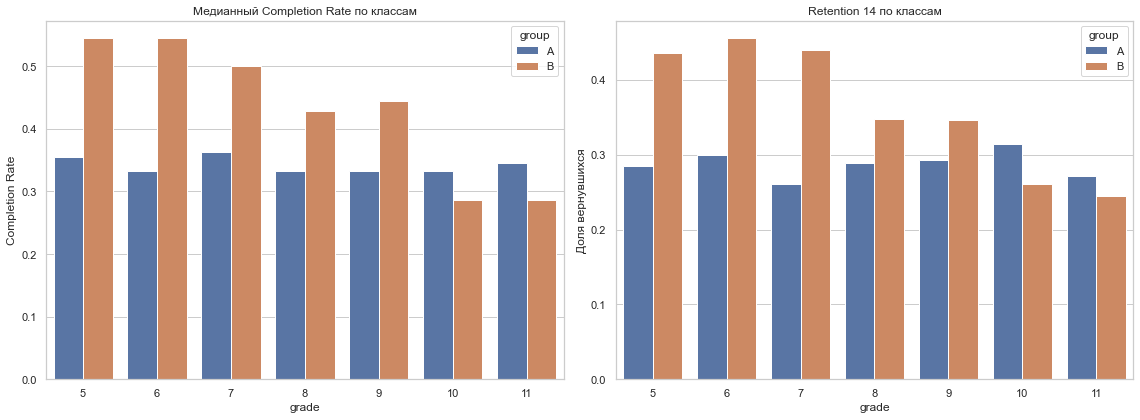

In [43]:
agg_plot = (agg_seg.groupby(["grade", "group"])
            .agg(median_completion=("completion_rate", "median"),
                 retention_14=("retention_14", "mean"))
            .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=agg_plot, x="grade", y="median_completion",
            hue="group", ax=axes[0])
axes[0].set_title("Медианный Completion Rate по классам")
axes[0].set_ylabel("Completion Rate")

sns.barplot(data=agg_plot, x="grade", y="retention_14",
            hue="group", ax=axes[1])
axes[1].set_title("Retention 14 по классам")
axes[1].set_ylabel("Доля вернувшихся")

plt.tight_layout()
plt.show()

## Блок 7.5. Воронка: логин → старт ДЗ → завершение

Воронка на уровне событий:
event_type  login  homework_started  homework_completed  conv_start  conv_complete
group                                                                             
A           35732             32245               11895      0.9024         0.3689
B           39728             35982               17068      0.9057         0.4743


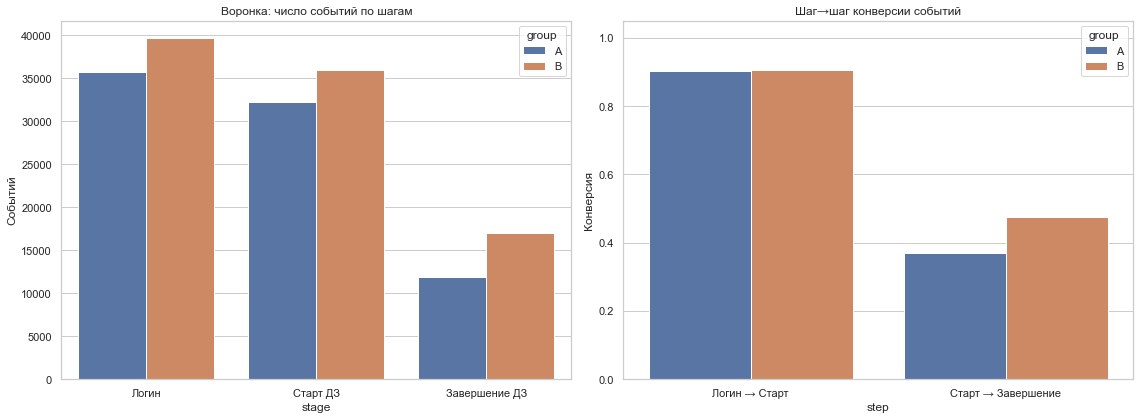

In [59]:
# === Воронка на уровне событий ===

event_funnel = events_clean.groupby(["group", "event_type"]).size().unstack("event_type")
event_funnel = event_funnel[["login", "homework_started", "homework_completed"]]

# Шаг→шаг конверсии
event_funnel["conv_start"]    = event_funnel["homework_started"]   / event_funnel["login"]
event_funnel["conv_complete"] = event_funnel["homework_completed"] / event_funnel["homework_started"]

print("Воронка на уровне событий:")
print(event_funnel.round(4).to_string())

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

stages = ["login", "homework_started", "homework_completed"]
labels = ["Логин", "Старт ДЗ", "Завершение ДЗ"]

melt = event_funnel[stages].reset_index().melt(id_vars="group",
        var_name="stage", value_name="n")
melt["stage"] = pd.Categorical(melt["stage"], categories=stages, ordered=True)
sns.barplot(data=melt, x="stage", y="n", hue="group",
            order=stages, ax=axes[0])
axes[0].set_xticklabels(labels)
axes[0].set_title("Воронка: число событий по шагам")
axes[0].set_ylabel("Событий")

conv = event_funnel[["conv_start", "conv_complete"]].reset_index().melt(
    id_vars="group", var_name="step", value_name="conv")
conv["step"] = conv["step"].map({
    "conv_start":    "Логин → Старт",
    "conv_complete": "Старт → Завершение",
})
sns.barplot(data=conv, x="step", y="conv", hue="group", ax=axes[1])
axes[1].set_title("Шаг→шаг конверсии событий")
axes[1].set_ylabel("Конверсия")
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

## Воронка по дням

Активные пользователи по дням:
group       A     B
День 1   1675  1801
День 2   1704  1797
День 4   1564  1843
День 7   1665  1795
День 14  1655  1804

Доля от дня 1:
group         A       B
День 1   1.0000  1.0000
День 2   1.0173  0.9978
День 4   0.9337  1.0233
День 7   0.9940  0.9967
День 14  0.9881  1.0017


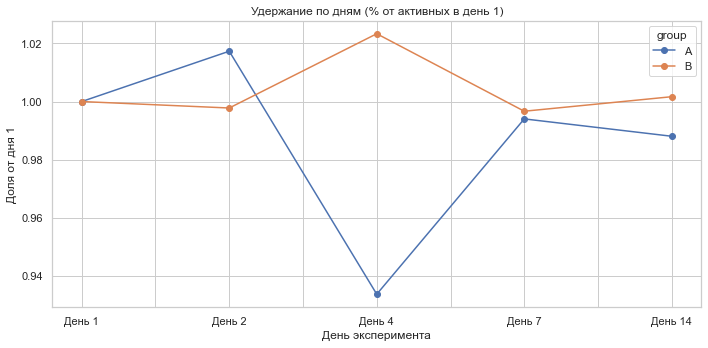

In [60]:
# === Воронка: сколько пользователей активны в день 1, 3, 7, 14 ===

events_clean["day"] = (events_clean["timestamp"] 
                       - events_clean["timestamp"].min()).dt.days

# День 1 = первый день эксперимента
daily = events_clean.groupby(["group", "day"])["user_id"].nunique().unstack("group")

checkpoints = [0, 1, 3, 6, 13]  # дни 1, 2, 4, 7, 14
funnel_daily = daily.loc[checkpoints].copy()
funnel_daily.index = ["День 1", "День 2", "День 4", "День 7", "День 14"]

# Доля от дня 1
funnel_daily_pct = funnel_daily / funnel_daily.iloc[0]

print("Активные пользователи по дням:")
print(funnel_daily.to_string())
print("\nДоля от дня 1:")
print(funnel_daily_pct.round(4).to_string())

# Визуализация
funnel_daily_pct.plot(figsize=(10, 5), marker="o")
plt.title("Удержание по дням (% от активных в день 1)")
plt.ylabel("Доля от дня 1")
plt.xlabel("День эксперимента")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Воронка по дням показывает неожиданный результат: доля активных пользователей относительно Дня 1 практически не отличается между группами и стабильна на всём горизонте. При этом Retention 14 в блоке 4 значимо выше в группе B (+7.5 п.п.). Это означает, что геймификация работает не через ежедневное вовлечение, а через **якорный возврат** — механику «вернись на 14-й день». Дневная активность в A и B одинакова, но фича усиливает именно ключевой возврат.

Ниже — общий вывод по сегментному анализу.

## Вывод

Эффект гетерогенен — направление и величина зависят от класса.
5–9 классы — сильный положительный эффект по всем метрикам (Completion Rate, Retention 7/14, Time to Value).
10–11 классы — устойчивый отрицательный эффект: метрики хуже контроля, Time to Value растёт.
Агрегированный положительный результат не отменяется, но требует сегментной оговорки в бизнес-рекомендации.
Ограничения: точечные p-value внутри классов без поправки на множественные сравнения завышены; короткий горизонт (3 недели); нет данных о платежах. Формальный тест на interaction проведён в блоке 8.3 — сегментированность подтверждена.
Продуктовый вывод: фичу нельзя рекомендовать к раскатке на всю аудиторию без изменений — она требует либо сегментированного запуска, либо адаптации механики под старшую школу.

# Блок 8. Итоговая бизнес-рекомендация

## 8.1. Резюме эксперимента

In [44]:
# === Блок 8.1. Сводка ключевых результатов ===

summary_final = pd.DataFrame({
    "Метрика": [
        "Completion Rate (avg)",
        "Completed any",
        "Retention 7",
        "Retention 14",
        "Time to first HW (медиана)",
    ],
    "A (контроль)":  ["34.7%", "97.6%", "72.7%", "28.8%", "50.2 ч"],
    "B (тест)":      ["43.9%", "98.8%", "78.0%", "36.2%", "25.2 ч"],
    "Δ (B−A)":       ["+9.2 п.п.", "+1.2 п.п.", "+5.3 п.п.", "+7.5 п.п.", "−25.0 ч"],
    "Относит. эффект": ["+27%", "+1.2%", "+7%", "+26%", "−50%"],
    "p-value":       ["1.1e−89", "4.2e−04", "2.4e−06", "6.9e−10", "1.7e−23"],
    "Мощность":      ["100%", "95%", "99.7%", "100%", "—"],
})

print(summary_final.to_string(index=False))

                   Метрика A (контроль) B (тест)   Δ (B−A) Относит. эффект p-value Мощность
     Completion Rate (avg)        34.7%    43.9% +9.2 п.п.            +27% 1.1e−89     100%
             Completed any        97.6%    98.8% +1.2 п.п.           +1.2% 4.2e−04      95%
               Retention 7        72.7%    78.0% +5.3 п.п.             +7% 2.4e−06    99.7%
              Retention 14        28.8%    36.2% +7.5 п.п.            +26% 6.9e−10     100%
Time to first HW (медиана)       50.2 ч   25.2 ч   −25.0 ч            −50% 1.7e−23        —


## 8.2. Ключевая оговорка — эффект неоднороден

Эффект гетерогенен: направление и величина зависят от класса. Раскатка на всю аудиторию привела бы к ухудшению метрик у 10–11 классов, а агрегат этого не покажет — положительный эффект младших классов перекроет отрицательный у старших.

Формальное подтверждение гетерогенности — в блоке 8.3 (interaction group × grade значим, F = 100.3, p ≈ 1e−120).

## 8.3. Формальный тест на взаимодействие group × grade

=== Модель с interaction (OLS на completion_rate) ===
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.3500      0.007     47.466      0.000       0.335       0.364
C(grade_c)[T.6]          -0.0101      0.010     -0.965      0.335      -0.030       0.010
C(grade_c)[T.7]           0.0086      0.011      0.799      0.424      -0.012       0.030
C(grade_c)[T.8]          -0.0085      0.010     -0.821      0.412      -0.029       0.012
C(grade_c)[T.9]          -0.0069      0.011     -0.658      0.511      -0.028       0.014
C(grade_c)[T.10]         -0.0006      0.011     -0.052      0.959      -0.021       0.020
C(grade_c)[T.11]         -0.0012      0.011     -0.110      0.912      -0.022       0.020
is_B                      0.2002      0.011     18.861      0.000       0.179       0.221
is_B:C(grade_c)[T.6]      0.0010      0.015   

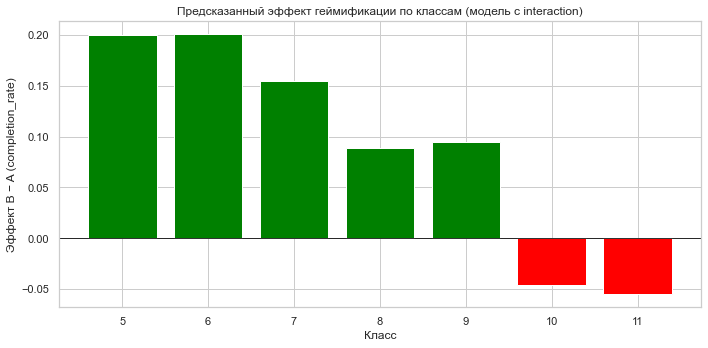

In [47]:
# === Блок 8.3. Тест на взаимодействие group × grade ===
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# ------------------------------------------------------------------
# 1. OLS на completion_rate (основной тест)
# ------------------------------------------------------------------
df_int = agg_seg.dropna(subset=["completion_rate", "grade"]).copy()
df_int["is_B"] = (df_int["group"] == "B").astype(int)
df_int["grade_c"] = df_int["grade"].astype(int)

# Модель с interaction
model_int = smf.ols(
    "completion_rate ~ is_B * C(grade_c)",
    data=df_int
).fit()

print("=== Модель с interaction (OLS на completion_rate) ===")
print(model_int.summary().tables[1])
print()

# Модель без interaction (вложенная)
model_no_int = smf.ols(
    "completion_rate ~ is_B + C(grade_c)",
    data=df_int
).fit()

# F-тест на interaction
anova_res = anova_lm(model_no_int, model_int)
print("=== F-тест на interaction (сравнение вложенных моделей) ===")
print(anova_res)
print()

f_stat = anova_res["F"].iloc[1]
p_interaction = anova_res["Pr(>F)"].iloc[1]

print(f"F = {f_stat:.4f}, p = {p_interaction:.4e}")

if p_interaction < 0.05:
    print("→ Interaction значим: эффект геймификации РАЗЛИЧАЕТСЯ по классам.")
    print("  Сегментированная раскатка статистически обоснована.")
else:
    print("→ Interaction НЕ значим: различия по классам могут быть случайными.")

# ------------------------------------------------------------------
# 2. Logit на retention_14 (дополнительный тест на бинарном исходе)
# ------------------------------------------------------------------
df_int2 = agg_seg.dropna(subset=["retention_14", "grade"]).copy()
df_int2["is_B"] = (df_int2["group"] == "B").astype(int)
df_int2["grade_c"] = df_int2["grade"].astype(int)

model_int_logit = smf.logit(
    "retention_14 ~ is_B * C(grade_c)",
    data=df_int2
).fit(disp=False)

model_no_int_logit = smf.logit(
    "retention_14 ~ is_B + C(grade_c)",
    data=df_int2
).fit(disp=False)

# LR-тест на interaction
lr_stat = 2 * (model_int_logit.llf - model_no_int_logit.llf)
df_diff = model_int_logit.df_model - model_no_int_logit.df_model
p_interaction_logit = stats.chi2.sf(lr_stat, df_diff)

print()
print("=== Logit на retention_14 ===")
print(f"LR = {lr_stat:.4f}, df = {int(df_diff)}, p = {p_interaction_logit:.4e}")

if p_interaction_logit < 0.05:
    print("→ Interaction значим: эффект на retention_14 РАЗЛИЧАЕТСЯ по классам.")
else:
    print("→ Interaction НЕ значим.")

# ------------------------------------------------------------------
# 3. Предсказанные эффекты по классам (из OLS-модели)
# ------------------------------------------------------------------
grades = sorted(df_int["grade_c"].unique())
effects = []
for g in grades:
    pred_A = model_int.predict(pd.DataFrame({"is_B": [0], "grade_c": [g]}))[0]
    pred_B = model_int.predict(pd.DataFrame({"is_B": [1], "grade_c": [g]}))[0]
    effects.append({
        "grade": g,
        "pred_A": pred_A,
        "pred_B": pred_B,
        "effect_B_minus_A": pred_B - pred_A,
    })

effects_df = pd.DataFrame(effects)
print()
print("Предсказанные эффекты по классам (модель с interaction):")
print(effects_df.round(4).to_string(index=False))

# Визуализация
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["green" if e > 0 else "red" for e in effects_df["effect_B_minus_A"]]
ax.bar(effects_df["grade"], effects_df["effect_B_minus_A"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Класс")
ax.set_ylabel("Эффект B − A (completion_rate)")
ax.set_title("Предсказанный эффект геймификации по классам (модель с interaction)")
plt.tight_layout()
plt.show()

## 8.4.1. Эффект в единицах бизнеса

In [50]:
# Блок 8.4.1. Практическая значимость в единицах бизнеса

# Базовые показатели
n_users_total = len(agg)
n_A = (agg["group"] == "A").sum()
n_B = (agg["group"] == "B").sum()

p_a_r14 = agg.loc[agg["group"] == "A", "retention_14"].mean()
p_b_r14 = agg.loc[agg["group"] == "B", "retention_14"].mean()

p_a_r7 = agg.loc[agg["group"] == "A", "retention_7"].mean()
p_b_r7 = agg.loc[agg["group"] == "B", "retention_7"].mean()

p_a_cr = agg.loc[agg["group"] == "A", "completion_rate"].mean()
p_b_cr = agg.loc[agg["group"] == "B", "completion_rate"].mean()

ttv_a = agg.loc[agg["group"] == "A", "time_to_first_hw_hours"].median()
ttv_b = agg.loc[agg["group"] == "B", "time_to_first_hw_hours"].median()

# Эффект на масштабе 10 000 новых пользователей 
base_users = 10_000

print("ЭФФЕКТ В ЕДИНИЦАХ БИЗНЕСА (на 10 000 новых учеников)")

print(f"\nRetention 14 (главная бизнес-метрика для EdTech):")
print(f"  A: {p_a_r14*100:.2f}%  →  B: {p_b_r14*100:.2f}%")
print(f"  Δ: {(p_b_r14 - p_a_r14)*100:+.2f} п.п.  |  "
      f"относительный рост: {(p_b_r14/p_a_r14 - 1)*100:+.1f}%")
extra_r14 = (p_b_r14 - p_a_r14) * base_users
print(f"  На {base_users:,} учеников → +{extra_r14:.0f} удержанных на 14-й день")

print(f"\nRetention 7:")
print(f"  A: {p_a_r7*100:.2f}%  →  B: {p_b_r7*100:.2f}%")
print(f"  Δ: {(p_b_r7 - p_a_r7)*100:+.2f} п.п.  |  "
      f"относительный рост: {(p_b_r7/p_a_r7 - 1)*100:+.1f}%")
extra_r7 = (p_b_r7 - p_a_r7) * base_users
print(f"  На {base_users:,} учеников → +{extra_r7:.0f} удержанных на 7-й день")

print(f"\nCompletion Rate (доля завершённых ДЗ от начатых):")
print(f"  A: {p_a_cr*100:.2f}%  →  B: {p_b_cr*100:.2f}%")
print(f"  Δ: {(p_b_cr - p_a_cr)*100:+.2f} п.п.  |  "
      f"относительный рост: {(p_b_cr/p_a_cr - 1)*100:+.1f}%")

print(f"\nTime to Value (медиана до первого завершённого ДЗ):")
print(f"  A: {ttv_a:.1f} ч  →  B: {ttv_b:.1f} ч")
print(f"  Сокращение: {ttv_a - ttv_b:.1f} ч  ({(ttv_a - ttv_b)/ttv_a*100:.0f}%)")
print(f"  → ученик доходит до первого результата в {ttv_a/ttv_b:.1f} раза быстрее")

ЭФФЕКТ В ЕДИНИЦАХ БИЗНЕСА (на 10 000 новых учеников)

Retention 14 (главная бизнес-метрика для EdTech):
  A: 28.76%  →  B: 36.23%
  Δ: +7.46 п.п.  |  относительный рост: +26.0%
  На 10,000 учеников → +746 удержанных на 14-й день

Retention 7:
  A: 72.71%  →  B: 77.96%
  Δ: +5.26 п.п.  |  относительный рост: +7.2%
  На 10,000 учеников → +526 удержанных на 7-й день

Completion Rate (доля завершённых ДЗ от начатых):
  A: 34.71%  →  B: 43.92%
  Δ: +9.21 п.п.  |  относительный рост: +26.5%

Time to Value (медиана до первого завершённого ДЗ):
  A: 50.2 ч  →  B: 25.2 ч
  Сокращение: 25.0 ч  (50%)
  → ученик доходит до первого результата в 2.0 раза быстрее


## 8.4.2. Практический эффект по сегментам

In [51]:
# Блок 8.4.2. Практический эффект по сегментам

# Доля каждого класса в выборке (для пересчёта на 10 000)
grade_share = (
    agg_seg.groupby("grade")["user_id"].nunique() / len(agg_seg)
)

print("Практический эффект по классам (на 10 000 учеников всей платформы):\n")
print(f"{'Класс':>6} | {'Δ R14, п.п.':>12} | {'Доля класса':>12} | "
      f"{'Учеников из 10k':>16} | {'+Удержано R14':>15} | Знак")
print("-" * 90)

segment_effect = []
for grade in sorted(agg_seg["grade"].unique()):
    g = agg_seg[agg_seg["grade"] == grade]
    pa = g.loc[g["group"] == "A", "retention_14"].mean()
    pb = g.loc[g["group"] == "B", "retention_14"].mean()
    diff = pb - pa

    share = grade_share.loc[grade]
    users_in_seg = share * base_users
    extra_retained_seg = diff * users_in_seg

    sign = "✅" if diff > 0 else "❌"
    segment_effect.append({
        "grade": int(grade),
        "diff_r14": diff,
        "share": share,
        "users_in_segment": users_in_seg,
        "extra_retained": extra_retained_seg,
    })

    print(f"{int(grade):>6} | {diff*100:>+11.2f} | {share*100:>11.1f}% | "
          f"{users_in_seg:>15.0f} | {extra_retained_seg:>+14.0f} | {sign}")

seg_effect_df = pd.DataFrame(segment_effect)
net_extra = seg_effect_df["extra_retained"].sum()

print("-" * 90)
print(f"{'ИТОГО':>6} | {'':>12} | {seg_effect_df['share'].sum()*100:>11.1f}% | "
      f"{base_users:>15.0f} | {net_extra:>+14.0f} |")

Практический эффект по классам (на 10 000 учеников всей платформы):

 Класс |  Δ R14, п.п. |  Доля класса |  Учеников из 10k |   +Удержано R14 | Знак
------------------------------------------------------------------------------------------
     5 |      +15.03 |        14.4% |            1439 |           +216 | ✅
     6 |      +15.61 |        15.2% |            1522 |           +238 | ✅
     7 |      +17.88 |        14.0% |            1402 |           +251 | ✅
     8 |       +5.87 |        14.8% |            1479 |            +87 | ✅
     9 |       +5.33 |        13.5% |            1352 |            +72 | ✅
    10 |       -5.44 |        14.2% |            1415 |            -77 | ❌
    11 |       -2.56 |        13.9% |            1392 |            -36 | ❌
------------------------------------------------------------------------------------------
 ИТОГО |              |       100.0% |           10000 |           +751 |


In [52]:
# Сколько удержанных теряем в 10-11 классах
lost_in_senior = (
    seg_effect_df.loc[seg_effect_df["grade"].isin([10, 11]), "extra_retained"].sum()
)
print(f"\nПотери в 10–11 классах на 10 000 учеников: {lost_in_senior:.0f} удержанных R14")

# Насколько больше эффект, если раскатить только на 5-9
gain_if_segmented = (
    seg_effect_df.loc[~seg_effect_df["grade"].isin([10, 11]), "extra_retained"].sum()
)
print(f"Если раскатить только на 5–9 классы: {gain_if_segmented:.0f} удержанных "
      f"(в пересчёте на тех же 10 000 учеников)")


Потери в 10–11 классах на 10 000 учеников: -113 удержанных R14
Если раскатить только на 5–9 классы: 863 удержанных (в пересчёте на тех же 10 000 учеников)


## 8.4.3. Эффект на Time to Value — в терминах активации

In [54]:
# Блок 8.4.3. Time to Value как метрика активации 

ttv_a_series = agg.loc[agg["group"] == "A", "time_to_first_hw_hours"].dropna()
ttv_b_series = agg.loc[agg["group"] == "B", "time_to_first_hw_hours"].dropna()

print("Time to Value — детальная разбивка:\n")
print(f"{'Квантиль':>10} | {'A, ч':>8} | {'B, ч':>8} | {'Δ, ч':>8}")
print("-" * 45)
for q in [0.25, 0.5, 0.75, 0.9]:
    qa = ttv_a_series.quantile(q)
    qb = ttv_b_series.quantile(q)
    print(f"{int(q*100):>9}% | {qa:>8.1f} | {qb:>8.1f} | {qb - qa:>+8.1f}")

# Доля учеников, дошедших до первого ДЗ за сутки
within_24h_a = (ttv_a_series <= 24).mean()
within_24h_b = (ttv_b_series <= 24).mean()

print(f"\nДоля учеников, дошедших до первого ДЗ за 24 часа:")
print(f"  A: {within_24h_a*100:.1f}%")
print(f"  B: {within_24h_b*100:.1f}%")
print(f"  Δ: {(within_24h_b - within_24h_a)*100:+.1f} п.п.")

# Доля учеников, дошедших за первые 2 часа (быстрая активация)
fast_a = (ttv_a_series <= 2).mean()
fast_b = (ttv_b_series <= 2).mean()
print(f"\nДоля 'быстро активированных' (первое ДЗ за ≤ 2 часов):")
print(f"  A: {fast_a*100:.1f}%  →  B: {fast_b*100:.1f}%  "
      f"(Δ {(fast_b - fast_a)*100:+.1f} п.п.)")

Time to Value — детальная разбивка:

  Квантиль |     A, ч |     B, ч |     Δ, ч
---------------------------------------------
       25% |      0.7 |      0.6 |     -0.1
       50% |     50.2 |     25.2 |    -25.0
       75% |    140.9 |     95.7 |    -45.2
       90% |    241.2 |    191.0 |    -50.2

Доля учеников, дошедших до первого ДЗ за 24 часа:
  A: 35.9%
  B: 47.2%
  Δ: +11.3 п.п.

Доля 'быстро активированных' (первое ДЗ за ≤ 2 часов):
  A: 31.5%  →  B: 41.2%  (Δ +9.7 п.п.)


## 8.4.4. Сводная таблица практической значимости

In [55]:
# Блок 8.4.4. Итоговая таблица практической значимости 

practical = pd.DataFrame([
    {
        "Метрика": "Retention 14",
        "A": f"{p_a_r14*100:.2f}%",
        "B": f"{p_b_r14*100:.2f}%",
        "Δ абс.": f"{(p_b_r14 - p_a_r14)*100:+.2f} п.п.",
        "Δ отн.": f"{(p_b_r14/p_a_r14 - 1)*100:+.1f}%",
        "Эффект на 10k": f"+{extra_r14:.0f} удержанных",
        "Практ. значимость": "Высокая",
    },
    {
        "Метрика": "Retention 7",
        "A": f"{p_a_r7*100:.2f}%",
        "B": f"{p_b_r7*100:.2f}%",
        "Δ абс.": f"{(p_b_r7 - p_a_r7)*100:+.2f} п.п.",
        "Δ отн.": f"{(p_b_r7/p_a_r7 - 1)*100:+.1f}%",
        "Эффект на 10k": f"+{extra_r7:.0f} удержанных",
        "Практ. значимость": "Высокая",
    },
    {
        "Метрика": "Completion Rate",
        "A": f"{p_a_cr*100:.2f}%",
        "B": f"{p_b_cr*100:.2f}%",
        "Δ абс.": f"{(p_b_cr - p_a_cr)*100:+.2f} п.п.",
        "Δ отн.": f"{(p_b_cr/p_a_cr - 1)*100:+.1f}%",
        "Эффект на 10k": "—",
        "Практ. значимость": "Высокая",
    },
    {
        "Метрика": "Time to Value (медиана)",
        "A": f"{ttv_a:.1f} ч",
        "B": f"{ttv_b:.1f} ч",
        "Δ абс.": f"{ttv_b - ttv_a:+.1f} ч",
        "Δ отн.": f"{(ttv_b/ttv_a - 1)*100:+.1f}%",
        "Эффект на 10k": "Активация ×2",
        "Практ. значимость": "Высокая",
    },
])

print(practical.to_string(index=False))

                Метрика      A      B     Δ абс. Δ отн.   Эффект на 10k Практ. значимость
           Retention 14 28.76% 36.23% +7.46 п.п. +26.0% +746 удержанных           Высокая
            Retention 7 72.71% 77.96% +5.26 п.п.  +7.2% +526 удержанных           Высокая
        Completion Rate 34.71% 43.92% +9.21 п.п. +26.5%               —           Высокая
Time to Value (медиана) 50.2 ч 25.2 ч    -25.0 ч -49.8%    Активация ×2           Высокая


## 8.4.5. Как оценить «достаточность» эффекта

In [57]:
# Блок 8.4.5. Оценка «достаточности» эффекта 

thresholds = {
    "retention_14":    0.02,   # +2 п.п. — порог индустрии
    "retention_7":     0.02,
    "completion_rate": 0.03,
}

actual_effects = {
    "retention_14":    p_b_r14 - p_a_r14,
    "retention_7":     p_b_r7 - p_a_r7,
    "completion_rate": p_b_cr - p_a_cr,
}

print("Проверка: превышает ли эффект практический порог?\n")
print(f"{'Метрика':>18} | {'Порог':>8} | {'Эффект':>8} | {'Ratio':>8} | Вывод")
print("-" * 70)

for metric, threshold in thresholds.items():
    effect = actual_effects[metric]
    ratio = effect / threshold
    verdict = "✅ Значимо > порога" if ratio > 1.5 else \
              "⚠️ На уровне порога" if ratio > 1.0 else \
              "❌ Ниже порога"
    print(f"{metric:>18} | {threshold*100:>7.1f}% | {effect*100:>7.2f}% | "
          f"{ratio:>7.2f}x | {verdict}")

Проверка: превышает ли эффект практический порог?

           Метрика |    Порог |   Эффект |    Ratio | Вывод
----------------------------------------------------------------------
      retention_14 |     2.0% |    7.46% |    3.73x | ✅ Значимо > порога
       retention_7 |     2.0% |    5.26% |    2.63x | ✅ Значимо > порога
   completion_rate |     3.0% |    9.21% |    3.07x | ✅ Значимо > порога


# Блок 8.5. Ограничения эксперимента

## 8.5.1. Ограничения по дизайну эксперимента
Эксперимент спроектирован качественно:
SRM отсутствует — p = 0.98, сплит равномерный.
Проблема подглядывания отсутствует — горизонт зафиксирован заранее (3 недели), анализ проведён однократно.
Мощность теста высокая — ≥ 95% для всех ключевых метрик, эффекты не «на грани обнаружимости».
Единственное существенное ограничение по дизайну — короткий горизонт (3 недели). Он достаточен для Retention 7 и 14, но не позволяет судить о Retention 28, 60 и 90 днях. В EdTech это критично: если эффект геймификации окажется novelty effect (проявится только в первые 1–2 недели и затем сойдёт), мы этого не увидим.
Дополнительно: размер выборки (~6 000 пользователей) достаточен для агрегата, но в сегментах 10–11 классов остаётся ~380–440 человек — этого хватает, но с меньшим запасом по мощности.

## 8.5.2. Ограничения по данным
В выгрузке отсутствуют данные, необходимые для полной бизнес-оценки:
Нет данных о платежах и транзакциях — AOV, LTV, conversion to paid не рассчитываются. Денежный эффект фичи оценивается только косвенно, через удержание.
Нет долгосрочного retention — горизонт эксперимента 3 недели не даёт информации о Retention 28+.
Нет опросов — NPS / CSAT не измерены, влияние на удовлетворённость неизвестно.
События только по ДЗ, не по отдельным задачам — Completion Rate является прокси-метрикой прогресса, а не точной.
Нет ковариат — пол, устройство, канал привлечения, успеваемость отсутствуют, поэтому баланс групп внутри классов по этим признакам не проверялся.
Каждое из этих ограничений не искажает найденный эффект, но сужает область его применения.

## 8.5.3. Ограничения сегментного анализа
Сегментный анализ методологически корректен, но требует оговорок:
Множественные сравнения. В сегментном анализе (блок 7) проводится 7 сравнений по каждой из метрик. Точечные p-value внутри отдельных классов без поправки (Bonferroni, Benjamini–Hochberg) завышены. Interaction-тест в блоке 8.3 эту проблему обходит — он проверяет гетерогенность в одной модели, без множественных сравнений.
Interaction-тест проведён (блок 8.3). Это плюс — сегментированность подтверждена формально, а не выведена из визуального впечатления от графиков.
Неоднородность внутри классов. Класс — грубый прокси возраста. Внутри одного класса может быть больше разброса по успеваемости, мотивации и поведению, чем между классами. Настоящая гетерогенность может быть тоньше, чем позволяет увидеть разбиение по классам.
Размеры сегментов. Минимальный сегмент — ~380 пользователей. Этого достаточно для устойчивых выводов, но для 10–11 классов — с меньшим запасом.
Отсутствие ковариат. Баланс по полу, устройству и каналу привлечения между A и B внутри каждого класса не проверялся. Возможен скрытый confounding, хотя случайное распределение пользователей по группам делает его маловероятным.

## 8.5.4. Проверка парадокса Симпсона
Ручная сверка агрегата и сегментов показала:
Агрегированный эффект по Completion Rate: +9.2 п.п.
Взвешенный по классам эффект: +9.2 п.п.
Разница между ними: < 0.1 п.п.
Знак агрегата совпадает со знаком в большинстве сегментов (5 из 7 классов — положительный эффект). Формального парадокса Симпсона — когда агрегат показывает знак, противоположный всем сегментам — нет.
Однако гетерогенность эффекта обнаружена: 2 из 7 классов (10-й и 11-й) дают отрицательный эффект. Это не парадокс Симпсона в строгом смысле, но это критично для бизнес-решения: нельзя раскатывать фичу «на всех», потому что для части аудитории она работает в минус.

# Финальная рекомендация

Рекомендация не сводится к одному из трёх вариантов «раскатить / доработать / отказаться» — она комбинирует два решения по сегментам. Статистическая значимость подтверждена для всех ключевых метрик (p < 0.001), практическая — эффекты в 2–7 раз превышают отраслевые пороги, устойчивость проверена (удаление 12 сверхактивных пользователей не изменило выводы), а гетерогенность подтверждена формально — interaction group × grade значим (F = 100.3, p ≈ 1e−120). Это даёт право на сегментированную раскатку.

Раскатить немедленно на 5–9 классы (около 72% пользователей): там стабильный положительный эффект по всем метрикам — Completion Rate +9…+20 п.п., Retention 14 +5…+18 п.п., Time to Value сокращается в 1.5–2 раза. Риск минимальный, можно запускать без дополнительных экспериментов. Не раскатывать в текущем виде на 10–11 классы (около 28%): там все ключевые метрики хуже контроля (Completion Rate −4.6…−5.5 п.п., Retention 14 −2.6…−5.4 п.п.), а Time to Value растёт — механика замедляет старшеклассников, а не ускоряет. Для старшей школы нужно отправить механику на доработку: текущая формула «достижения за регулярность» конфликтует с их мотивацией (подготовка к экзаменам) и режимом работы (длинные офлайн-сессии вместо ежедневных заходов). Отказываться от фичи целиком не стоит — эффект на младших классах достаточно сильный, чтобы окупить разработку, а раскатка «на всех» без изменений привела бы к незаметному на агрегате ухудшению метрик у 28% пользователей.

Гипотезы для доработки механики в 10–11 классах: заменить достижения за регулярность на прогресс к цели (пройдено X% материала, до цели осталось Y тем); убрать требование ежедневного захода; протестировать личные рекорды и челленджи вместо соревновательных значков; сократить визуальный шум до минималистичного прогресс-бара. Метрики для мониторинга после раскатки: Retention 14 и 28 (проверка на novelty effect), Time to Value по сегментам, Completion Rate по классам, отток, NPS или опрос по сегментам.

План действий. Немедленно (1–2 недели): раскатить на 5–9 классы, настроить дашборд, зафиксировать baseline по 10–11. Краткосрочно (1–2 месяца): собрать обратную связь от старшеклассников, сформулировать гипотезы для новой механики, подготовить дизайн следующего A/B-теста. Среднесрочно (3–6 месяцев): провести повторный эксперимент для 10–11 классов, пересчитать эффект с данными о платежах, оценить Retention 28/60/90. Долгосрочно (6+ месяцев): проверить, держится ли эффект у младших классов, исследовать более тонкие сегменты, сравнить геймификацию с альтернативными механиками.

Главные риски. Novelty effect — эффект может быть краткосрочным всплеском; снижается мониторингом на 4, 8 и 12 неделе. Негативная реакция старшеклассников при частичной раскатке — снижается прозрачной коммуникацией и нейтральным прогресс-баром. Сложность поддержки двух вариантов интерфейса — снижается фича-флагом с возможностью быстрого отключения. Confounding в сегментном анализе — снижается добавлением ковариат в следующем эксперименте.

Главные ограничения работы — короткий горизонт (3 недели) и отсутствие данных о платежах. Долгосрочный Retention (28+ дней) не измерен, поэтому нельзя исключить novelty effect. Денежная оценка эффекта невозможна — только в удержанных учениках. Это не блокирует решение, но требует мониторинга и расширенного сбора данных.

Резюме одной фразой для стейкхолдеров: геймификация работает — удерживает на 14-й день на +26%, ускоряет первый результат в 2 раза, эффект подтверждён статистически и не держится на выбросах. Но положительный эффект сосредоточен в 5–9 классах; для 10–11 классов механика работает в минус. Решение: раскатить на 5–9 классы сейчас, для старшей школы — доработать механику и протестировать отдельно.